# 01 · Getting a feel for laser-scan point clouds

This notebook explores the kind of data Hexagon's AI models work on: **3D point clouds from a laser scanner**.
The scenes are synthetic (see `src/data.py`), but they reproduce the properties that make real scans hard:

| Property | Why it matters for the model and for deployment |
| --- | --- |
| Unordered sets of points | The network must not depend on point order → shared MLP + max-pool (PointNet) |
| Density falls with range (~1/r²) | Far objects have few points; classes look different near vs far |
| Range noise grows with distance | Thin structures (poles) get fuzzy far away |
| Outliers ("noise" class) | Dust, stray returns; also the outliers that stretch quantization ranges |
| Class imbalance | Ground dominates; poles and noise are rare → weighted loss, per-class IoU |
| Mixed feature ranges | Metres vs intensity in [0, 1] → normalization before quantization |

Run top to bottom. Section 6 uses the trained checkpoint if you've run `python -m src.train`.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import torch
from src.data import (make_scene, to_model_input, SyntheticScans, class_frequencies,
                      CLASS_NAMES, CLASS_COLORS, NUM_CLASSES, SCANNER_HEIGHT, SCENE_RADIUS)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("project root:", ROOT)

project root: /home/claude/pointcloud-seg-edge


## 1. One scan, three views

A scan is just an `(N, 3)` array of coordinates plus per-point features (here: intensity) and, for training, a label per point.
The scanner sits at the origin, 1.8 m above the ground.

xyz (8192, 3) float32 | intensity (8192,) | labels (8192,) int64


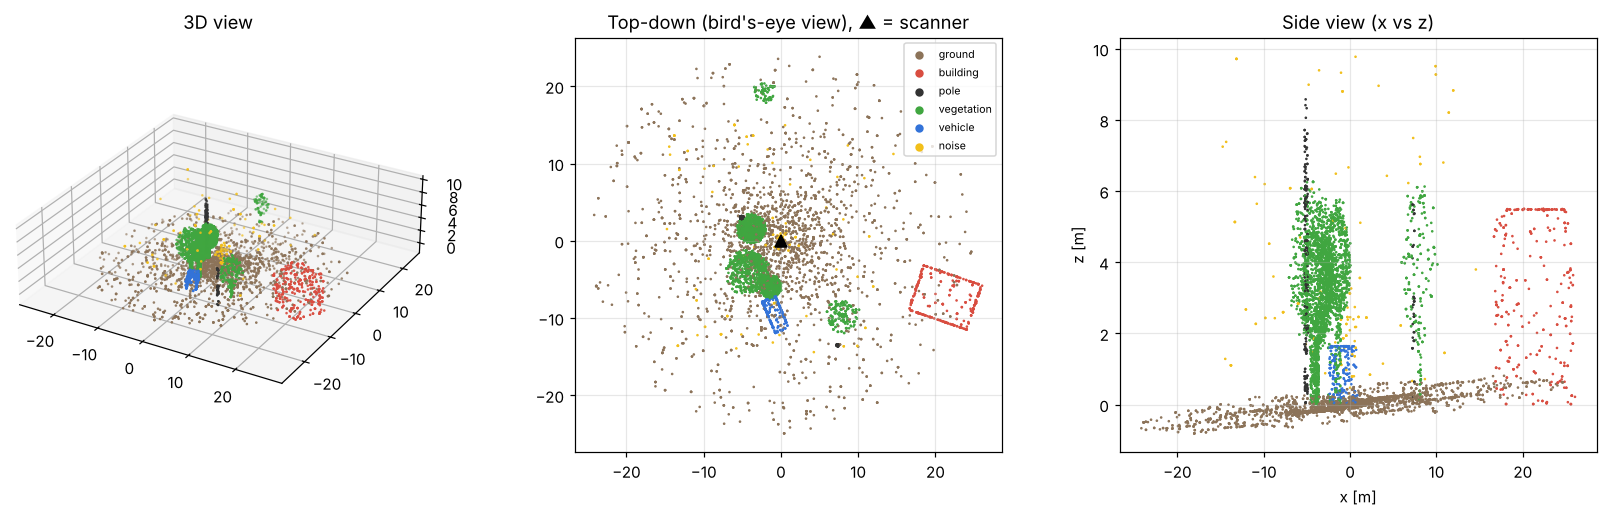

In [2]:
rng = np.random.default_rng(7)
xyz, intensity, labels = make_scene(rng, n_points=8192)   # more points than the model uses, for nicer plots
print("xyz", xyz.shape, xyz.dtype, "| intensity", intensity.shape, "| labels", labels.shape, labels.dtype)

def legend(ax):
    for c, name in enumerate(CLASS_NAMES):
        ax.scatter([], [], color=CLASS_COLORS[c], label=name, s=20)
    ax.legend(loc="upper right", fontsize=7, framealpha=0.8)

fig = plt.figure(figsize=(15, 4.8))
ax = fig.add_subplot(131, projection="3d")
ax.scatter(*xyz.T, c=CLASS_COLORS[labels], s=0.5)
ax.view_init(elev=28, azim=-60); ax.set_title("3D view"); ax.set_box_aspect((1, 1, 0.3))
ax = fig.add_subplot(132)
ax.scatter(xyz[:, 0], xyz[:, 1], c=CLASS_COLORS[labels], s=0.5)
ax.plot(0, 0, "k^", ms=8); ax.set_aspect("equal"); ax.set_title("Top-down (bird's-eye view), ▲ = scanner"); legend(ax)
ax = fig.add_subplot(133)
ax.scatter(xyz[:, 0], xyz[:, 2], c=CLASS_COLORS[labels], s=0.5)
ax.set_title("Side view (x vs z)"); ax.set_xlabel("x [m]"); ax.set_ylabel("z [m]")
plt.tight_layout(); plt.show()

**What to notice:** points cluster near the scanner and thin out with distance; buildings show up as walls (the scanner sees surfaces, not volumes);
tree canopies are fuzzy shells; yellow "noise" points float in free space.

## 2. Class balance

The model is evaluated per class (IoU), so rare classes matter even if they are few points.

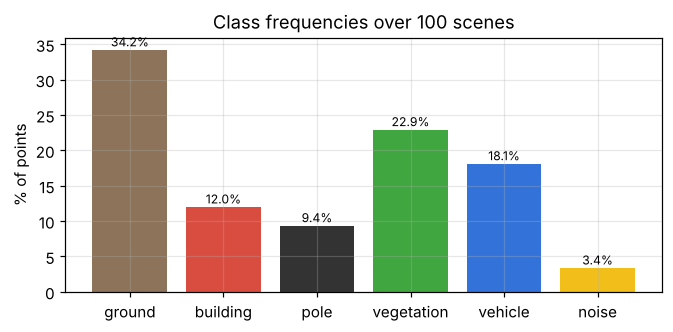

inverse-sqrt-frequency loss weights used in training: {'ground': 0.58, 'building': 0.98, 'pole': 1.11, 'vegetation': 0.71, 'vehicle': 0.79, 'noise': 1.84}


In [3]:
freq = class_frequencies(n_scenes=100)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(CLASS_NAMES, freq * 100, color=CLASS_COLORS)
for i, f in enumerate(freq):
    ax.text(i, f * 100 + 0.5, f"{f*100:.1f}%", ha="center", fontsize=8)
ax.set_ylabel("% of points"); ax.set_title("Class frequencies over 100 scenes")
plt.show()
w = 1 / np.sqrt(freq); w /= w.mean()
print("inverse-sqrt-frequency loss weights used in training:", {n: round(float(v), 2) for n, v in zip(CLASS_NAMES, w)})

## 3. Density and noise grow with range

Real scanners sample the world at fixed angular steps, so the number of points per square metre falls roughly with 1/r².
That is why the same object looks completely different at 5 m and at 20 m.

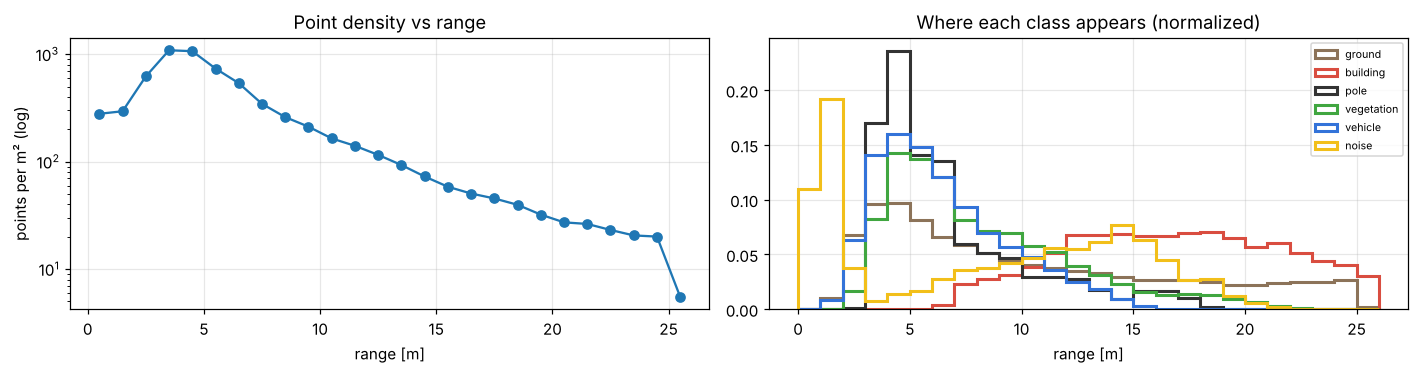

In [4]:
scanner = np.array([0, 0, SCANNER_HEIGHT])
big = [make_scene(np.random.default_rng(100 + i), n_points=8192) for i in range(30)]
r_all = np.concatenate([np.linalg.norm(s[0] - scanner, axis=1) for s in big])
l_all = np.concatenate([s[2] for s in big])

bins = np.arange(0, 27, 1.0)
counts, _ = np.histogram(r_all, bins)
ring_area = np.pi * (bins[1:]**2 - bins[:-1]**2)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
axs[0].semilogy(bins[:-1] + 0.5, counts / ring_area, "o-")
axs[0].set_xlabel("range [m]"); axs[0].set_ylabel("points per m² (log)"); axs[0].set_title("Point density vs range")
for c in range(NUM_CLASSES):
    axs[1].hist(r_all[l_all == c], bins=bins, histtype="step", lw=2, color=CLASS_COLORS[c], label=CLASS_NAMES[c], density=True)
axs[1].set_xlabel("range [m]"); axs[1].set_title("Where each class appears (normalized)"); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. Intensity: a second sensor channel

Intensity depends on the material (metal cars reflect strongly, vegetation weakly) and fades with range.

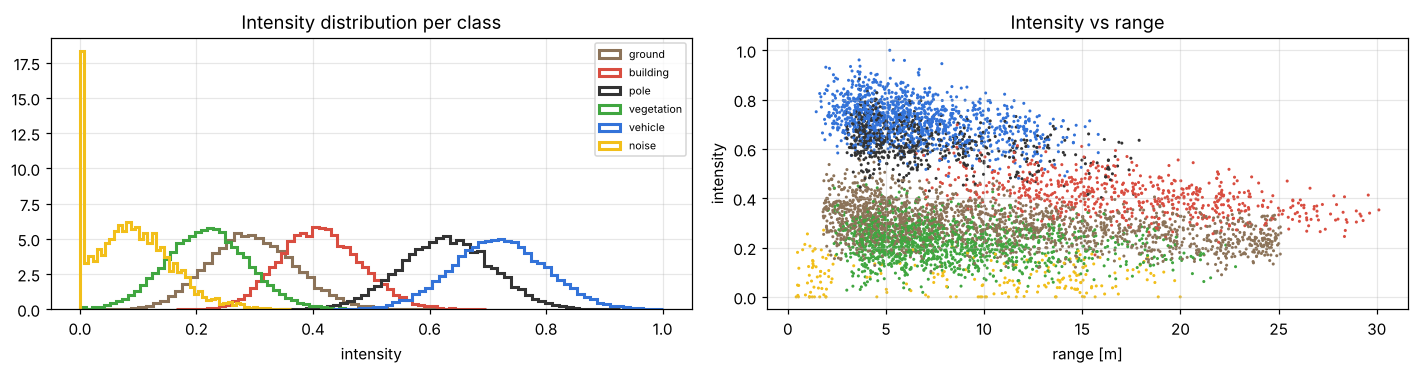

In [5]:
i_all = np.concatenate([s[1] for s in big])
fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
for c in range(NUM_CLASSES):
    axs[0].hist(i_all[l_all == c], bins=50, histtype="step", lw=2, color=CLASS_COLORS[c], label=CLASS_NAMES[c], density=True)
axs[0].set_xlabel("intensity"); axs[0].set_title("Intensity distribution per class"); axs[0].legend(fontsize=7)
sel = np.random.default_rng(0).choice(len(r_all), 6000, replace=False)
axs[1].scatter(r_all[sel], i_all[sel], c=CLASS_COLORS[l_all[sel]], s=1)
axs[1].set_xlabel("range [m]"); axs[1].set_ylabel("intensity"); axs[1].set_title("Intensity vs range")
plt.tight_layout(); plt.show()

## 5. What the model actually sees

The network takes a tensor of shape **(batch, channels, points) = (1, 4, 2048)**: `x/R, y/R, z/R, intensity` with `R = 25 m`.

* **Fixed N = 2048:** each scan is randomly sampled to exactly 2048 points, so every tensor shape is static. That's what
  an NPU compiler needs (same idea as padding to 56 agents / 200 lanes in a trajectory model).
* **Normalization:** raw coordinates span ±25 m while intensity spans [0, 1]. Notebook 02 shows why mixing those ranges
  in one tensor is bad for per-tensor input quantization.

In [6]:
x_raw = np.concatenate([xyz, intensity[:, None]], 1)
x_model = to_model_input(xyz, intensity)            # (4, N)
print("channel     raw min/max            model-input min/max")
for c, name in enumerate(["x", "y", "z", "intensity"]):
    print(f"{name:10s} {x_raw[:, c].min():8.2f} {x_raw[:, c].max():8.2f}      {x_model[c].min():8.3f} {x_model[c].max():8.3f}")

channel     raw min/max            model-input min/max
x            -24.17    26.04        -0.967    1.042
y            -24.93    23.82        -0.997    0.953
z             -0.81     9.78        -0.032    0.391
intensity      0.00     0.87         0.000    0.871


## 6. Order doesn't matter: why PointNet uses a max-pool

A point cloud is a *set*. If we shuffle the points, the per-point predictions must shuffle the same way, and the global
scene feature (the max over all points) must not change at all. Let's verify that on the network.

In [7]:
from src.model import PointNetSeg, load_checkpoint
ckpt_path = Path("outputs/checkpoints/pointnet_seg.pt")
model = load_checkpoint(str(ckpt_path))[0] if ckpt_path.exists() else PointNetSeg().eval()
print("using", "trained checkpoint" if ckpt_path.exists() else "an untrained model (run python -m src.train for the real one)")

ds = SyntheticScans("test", 4)
x, y = ds[0]
perm = torch.randperm(x.shape[1])
with torch.no_grad():
    out = model(x[None])
    out_perm = model(x[None, :, perm])
    g = torch.amax(model.glob(model.local(x[None])), 2)
    g_perm = torch.amax(model.glob(model.local(x[None, :, perm])), 2)
print("max |global feature - shuffled global feature|:", float((g - g_perm).abs().max()))
print("max |logits[perm] - logits(shuffled input)|:   ", float((out[..., perm] - out_perm).abs().max()))

using trained checkpoint
max |global feature - shuffled global feature|: 0.0
max |logits[perm] - logits(shuffled input)|:    0.0


## 7. Deployment-friendly representations

Point-based networks need ops like k-nearest-neighbours and gather/scatter that many NPUs handle poorly.
Two common tricks turn a point cloud into something regular:

* **Voxel-grid downsampling:** keep one point per voxel (also the classic way to even out density),
* **Range-image projection:** map each point to (elevation, azimuth) pixels, then use a normal 2D CNN (RangeNet++, SalsaNext).

voxel 0.10 m ->   9122 points (from 20000)
voxel 0.25 m ->   7515 points (from 20000)
voxel 0.50 m ->   5312 points (from 20000)
voxel 1.00 m ->   2884 points (from 20000)


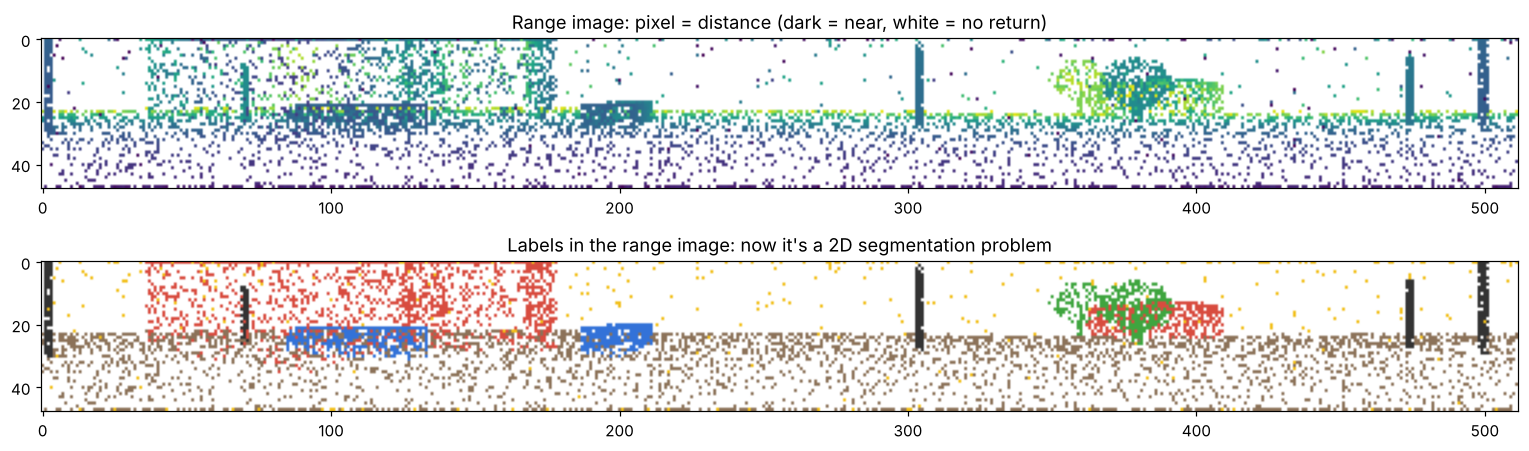

pixels filled: 23% (empty pixels = sky or missing returns)


In [8]:
def voxel_downsample(points, labels, voxel=0.5):
    keys = np.floor(points / voxel).astype(np.int64)
    _, first = np.unique(keys, axis=0, return_index=True)
    return points[first], labels[first]

xyz_big, int_big, lab_big = make_scene(np.random.default_rng(7), n_points=20000)
for v in (0.1, 0.25, 0.5, 1.0):
    print(f"voxel {v:4.2f} m -> {len(voxel_downsample(xyz_big, lab_big, v)[0]):6d} points (from {len(xyz_big)})")

def range_image(points, labels, H=48, W=512, fov_up=25.0, fov_down=-35.0):
    rel = points - np.array([0, 0, SCANNER_HEIGHT])
    r = np.linalg.norm(rel, axis=1)
    yaw = np.arctan2(rel[:, 1], rel[:, 0])
    pitch = np.arcsin(rel[:, 2] / np.maximum(r, 1e-6))
    u = ((1 - (pitch - np.radians(fov_down)) / np.radians(fov_up - fov_down)) * H).astype(int).clip(0, H - 1)
    v = ((0.5 * (1 - yaw / np.pi)) * W).astype(int).clip(0, W - 1)
    rimg = np.full((H, W), np.nan); limg = np.full((H, W), -1)
    order = np.argsort(-r)            # write far points first, so the nearest point wins each pixel
    rimg[u[order], v[order]] = r[order]; limg[u[order], v[order]] = labels[order]
    return rimg, limg

rimg, limg = range_image(xyz_big, lab_big)
fig, axs = plt.subplots(2, 1, figsize=(14, 4.2))
axs[0].imshow(rimg, cmap="viridis", aspect="auto"); axs[0].set_title("Range image: pixel = distance (dark = near, white = no return)")
lab_rgb = np.ones(limg.shape + (3,)); lab_rgb[limg >= 0] = CLASS_COLORS[limg[limg >= 0]]
axs[1].imshow(lab_rgb, aspect="auto"); axs[1].set_title("Labels in the range image: now it's a 2D segmentation problem")
for a in axs: a.grid(False)
plt.tight_layout(); plt.show()
print(f"pixels filled: {np.isfinite(rimg).mean()*100:.0f}% (empty pixels = sky or missing returns)")

## 8. Predictions of the trained model

Run `python -m src.train` first. Left: ground truth, middle: prediction, right: errors.

test mIoU 0.828   overall accuracy 0.942
ground: 0.98  building: 0.84  pole: 0.67  vegetation: 0.90  vehicle: 0.90  noise: 0.68


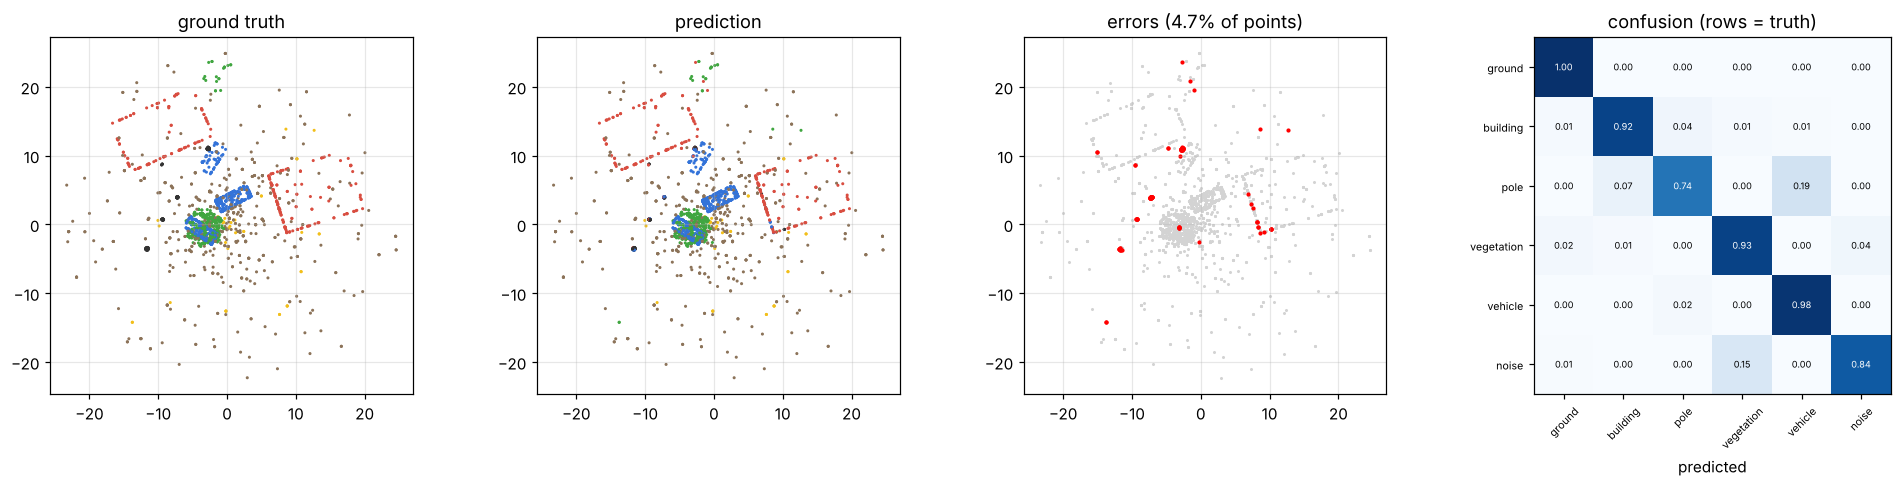

In [9]:
from src.metrics import confusion_matrix, summarize
if not ckpt_path.exists():
    print("No checkpoint yet - run: python -m src.train")
else:
    ds = SyntheticScans("test", 50)
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    with torch.no_grad():
        for i in range(len(ds)):
            x, y = ds[i]
            cm += confusion_matrix(model(x[None]).argmax(1).numpy(), y.numpy()[None])
    res = summarize(cm)
    print(f"test mIoU {res['mIoU']:.3f}   overall accuracy {res['OA']:.3f}")
    print("  ".join(f"{n}: {res['IoU_'+n]:.2f}" for n in CLASS_NAMES))

    x, y = ds[3]
    with torch.no_grad():
        pred = model(x[None]).argmax(1)[0].numpy()
    pts = x.numpy()[:3].T * SCENE_RADIUS; y = y.numpy()
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.4), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
    axs[0].scatter(pts[:, 0], pts[:, 1], c=CLASS_COLORS[y], s=1); axs[0].set_title("ground truth")
    axs[1].scatter(pts[:, 0], pts[:, 1], c=CLASS_COLORS[pred], s=1); axs[1].set_title("prediction")
    wrong = pred != y
    axs[2].scatter(pts[~wrong, 0], pts[~wrong, 1], c="lightgrey", s=1); axs[2].scatter(pts[wrong, 0], pts[wrong, 1], c="red", s=3)
    axs[2].set_title(f"errors ({wrong.mean()*100:.1f}% of points)")
    for a in axs[:3]: a.set_aspect("equal")
    cmn = cm / cm.sum(1, keepdims=True)
    axs[3].imshow(cmn, cmap="Blues", vmin=0, vmax=1); axs[3].grid(False)
    axs[3].set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, fontsize=7); axs[3].set_yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=7)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            axs[3].text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
    axs[3].set_title("confusion (rows = truth)"); axs[3].set_xlabel("predicted")
    plt.tight_layout(); plt.show()

## Things to try

1. Which classes get confused, and is it worse far from the scanner? Bin the errors by range.
2. Increase `n_points` to 4096 in training. What happens to accuracy, MACs and latency?
3. Remove the intensity channel (`in_channels=3`). Which class suffers most, and why?
4. Train on voxel-downsampled scenes instead of random sampling. Does the far-range accuracy improve?
5. Interview angle: how would you tile a 50-million-point scan into fixed 2048-point blocks and merge the predictions?